# CS308 Машин сургалт Лаборатори 5, 6, (7?)

# 1-р хэсэг
# Numpy ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.
1. Өгөгдлийн багц түүний дүрслэл сургалтанд бэлтгэх
2. Энгийн мэдрэлийн сүлжээ үүсгэх шууд урсгал
3. Градиент тооцоолох гэдрэг урсгал
4. Сургалтыг хэрэгжүүлэх
5. Сургасан загварт дүн шинжилгээ хийх туслах параметрүүдийг тохируулах


Бид хиймэл мэдрэлийн сүлжээ гэж юу болохыг мэддэг бөгөөд 'урагшаа болон арагшаа тархах' талаар практик мэдлэгтэй болох болно. Зүгээр энгийн загвар дээр сургалтыг хэрэгжүүлэх болно.

> Дараах бичлэгээс илүү ихийг мэдэх боломжтой юм. [youtube playlist](https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi) by [3Blue1Brown](https://www.3blue1brown.com/).

> youtube: https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi

## Ашиглах сангууд:

In [1]:
import numpy as np
import gzip
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from time import time

In [2]:
#hide_input
import warnings
np.random.seed(123)
%matplotlib inline
warnings.filterwarnings("ignore")

## Өгөгдлийг бэлтгэх

Энэхүү практик дадлагад бид компьютерийн хараанд хамгийн түгээмэл  датасетуудын нэгийг ашиглах болно, [MNIST](https://en.wikipedia.org/wiki/MNIST_database). MNIST нь Стандартчилал, Технологийн Үндэсний Институтээс цуглуулж, Ян Лекун болон түүний хамтран зүтгэгчдийн машин судлах мэдээллийн сан болгон цуглуулсан гараар бичсэн тоонуудын зургийг агуулдаг. Lecun нь 1998 онд [Lenet-5](http://yann.lecun.com/exdb/lenet/)-д MNIST-ийг ашигласан бөгөөд гараар бичсэн тоон дарааллыг бодитоор хүлээн зөвшөөрч байгааг харуулсан анхны компьютерийн систем юм. Энэ бол АИ-ийн түүхэн дэх хамгийн чухал ололт амжилтуудын нэг байлаа.

In [2]:
from torchvision.datasets import MNIST
from torch.nn.functional import one_hot

train = MNIST(root='./data', train=True, download=True)
test = MNIST(root='./data', train=False, download=True)


x_train, y_train = train.data, train.targets
y_train = one_hot(y_train, num_classes=10)
x_train = x_train.reshape(-1, 28*28)/255

x_test, y_test = test.data, test.targets
y_test = one_hot(y_test, num_classes=10)
x_test = x_test.reshape(-1, 28*28)/255




print("Shape of x_train:",x_train.shape)
print("Shape of y_train:",y_train.shape)

print("Shape of x_test:",x_test.shape)
print("Shape of y_test:",y_test.shape)


Shape of x_train: torch.Size([60000, 784])
Shape of y_train: torch.Size([60000, 10])
Shape of x_test: torch.Size([10000, 784])
Shape of y_test: torch.Size([10000, 10])


**Бидэнд яагаад сургалт болон баталгаажуулалтын гэсэн өөр өөр багц хэрэгтэй вэ ?**

Дээрх видео бичлэгээс илүү ихийг мэдэж авч болно:

> youtube: https://youtu.be/1waHlpKiNyY?t=243

Өгөгдлийн сангаа харцгаая

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 

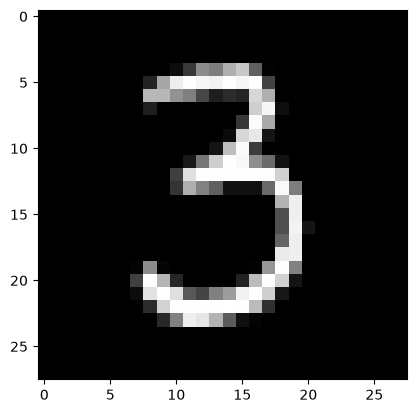

In [4]:
#collapse
plt.imshow(x_train[50].reshape(28,28), cmap="gray");
x_train[50]

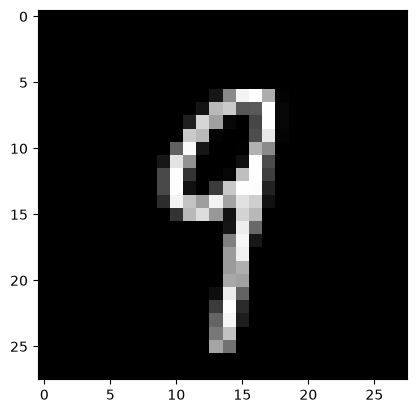

In [5]:
#collapse
plt.imshow(x_train[900].reshape(28,28), cmap="gray");

## Энгийн загварын архитектур

Энэ даалгаврын хувьд бид энэ 2 шугаман давхарга, 10 нэгж бүхий гаралтын давхаргыг маш энгийн загварын архитектурыг ашиглах болно.

In [6]:
#hide_input
import graphviz
def gv(s): return graphviz.Source('digraph G{ rankdir="LR"' + s + '; }')

## Энэ сүлжээ гэдэг нь юу гэсэн үг болохыг илүү дэлгэрэнгүй авч үзье:

Энэ сүлжээний бүх бүрэлдэхүүн хэсгүүдийг авч үзье:
- **Linear:**
  Шугаман давхарга нь дараах тооцооллыг хийнэ:      
   ```
   out = matmul(input,W1) + B1
   ```
   
- **ReLU:**
  ReLU нь дараах тооцооллыг хийнэ:
  ```
  out = max(0, input)
  ```
- **Sigmoid:**
  Sigmoid нь дараах тооцооллыг хийнэ:
  ```
  out = 1/(1 + e.pow(input))
  ```
  
- **Loss:**
  Бид алдагдалд дараах тэгшитгэлээр тодорхойлогдсон CrossEntropy алдагдлыг ашиглах болно:
  $$loss= -\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(yhat^{(i)}\right) + (1-y^{(i)})\log\left(1-yhat^{(i)}\right)) $$

**Одоо бид өөрсдийн загвар архитектуртай болсноор загварыг цуглуулахад шаардлагатай хэсгүүдийг бүтээцгээе:**
- linear layer
- relu activation
- sigmoid activation
- loss

**Эхлээд загварынхаа арагшаа, урагшаа дамжаанд юу болж байгааг ойлгохыг хичээе:**

**Судалгааны ажилын дагуу бидний загвар дараах байдалтай байна:**

> Тэмдэглэгээ: `@` python-д  `matrix-multiplication operator`.

```python
inputs = x_train # оролтууд
targets = y_train # шошго

# 1-р шугаман давхаргад урагш тархалт
z1 = inputs @ w2 + b2
a1 = relu(z1)
# 2-р шугаман давхаргад урагш тархалт
z2 = a1 @ w2 + b2
a2 = relu(z2)
# гаралт шугаман давхаргад урагш тархалт
z3 = a2 @ w3 + b3
pred = a3 = sigmoid(z3) # эдгээр нь бидний загварын таамаглалууд
# шошго болон таамаглалуудаас алдааг тодорхойлох
loss = loss_fn(a3, targets)
```
> Жич: Энэ бол бодит код биш зөвхөн ойлголтын psuedo-код юм.

**Урагш буюу шууд тархалт :**

In [7]:
#hide_input
gv('''
X->linear1->relu1->linear2->relu2->linear3->sigmoid->prediction

W1->linear1
B1->linear1

W2->linear2
B2->linear2

W3->linear3
B3->linear3
''')

ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH

In [8]:
#hide_input
gv('''
prediction->loss_fn
target->loss_fn
loss_fn-> loss
''')

ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH

**Мөн буцах буюу гэдрэг тархалт нь дараах байдалтай байна : (Гинжэн дүрэм)**

(Let us assume that the `grad(inp, out)` computes the gradients of `inp` wrt `out`)
(`grad(inp, out)` нь `inp`, `out` гэх мэтийн градиентуудыг тооцоолдог гэж бодъё)

```python
# сүүлийн идэвхжүүлэх давхаргын гаралтын алдагдлын gradient: (a3)
# (өөрөөр загварын таамаглалтууд)
da3 = grad(loss, a3)

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z3)
dz3 = grad(loss, z3) = grad(loss, a3) * grad(a3, z3)
# алдагдлын градиент w3 хүртэл
dw3 = grad(loss, w3) = grad(loss, z3) * grad(z3, w3) = dz3 * grad(z3, w3)
# алдагдлын градиент b3 хүртэл
db3 = grad(loss, b3) = grad(loss, z3) * grad(z3, b3) = dz3 * grad(z3, b3)
# одоогийн шугаман давхаргын оролт руу алдагдлын gradient: (a2)
da2 = grad(loss, a2) = grad(loss, a3) = grad(a2, )

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z2)
dz2 = grad(loss, z2) = grad(loss, a2) * grad(a2, z2)
# алдагдлын градиент w2 хүртэл
dw2 = grad(loss, w2) = grad(loss, z2) * grad(z2, w2) = dz2 * grad(z2, w2)
# алдагдлын градиент b2 хүртэл
db2 = grad(loss, b2) = grad(loss, z2) * grad(z2, b2) = dz2 * grad(z2, b2)
# одоогийн шугаман давхаргын оролт руу алдагдлын gradient: (a1)
da1 = grad(loss, a1) = grad(loss, z2) * grad(z2, a1) = dz2 * grad(z2, a1)

# одоогийн шугаман давхаргын гаралт руу алдагдлын gradient: (z1)
dz1 = grad(loss, z1) = grad(loss, a1) * grad(a1, z1) = da1 * grad(a1, z1)
# алдагдлын градиент w1 хүртэл
dw1 = grad(loss, w1) = grad(loss, z1) * grad(z1, w1) = dz1 * grad(z1, w1)
# алдагдлын градиент b1 хүртэл
db1 = grad(loss, b1) = grad(loss, z1) * grad(z1, 1) = dz1 * grad(z1, b1)
# Энэ давхаргад оролтууд нь бид илүү олон градиентыг тооцоолол хийх шаардлагагүй тулд бидний өөрчилж чадахгүй сургалтын жишээнүүд юм.

# parameter-үүдийг шинэчлэх :
# одоо бидэнд шаардлагатай бүх градиент байгаа болохоор бид одоо шинэчлэх алхмыг хийж болно.
w1 -= learning_rate * dw1
b1 -= learning_rate * db1

w2 -= learning_rate * dw2
b2 -= learning_rate * db2
```
> Жич: Энэ бол бодит код биш зөвхөн ойлголтын psuedo-код юм.

**Буцах чиглэл:**

In [9]:
#hide_input
gv('''
Loss -> sigmoid->linear3
linear3->W3
linear3->B3
linear3->relu2->linear2

linear2->W2
linear2->B2
linear2->relu1->linear1

linear1->W1
linear1->B1
''')

ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH

### `Linear` давхарга

Доорх код нь бидний мэдрэлийн сүлжээнд `Linear` давхаргыг төлөөлдөг `Linear class` үүсгэдэг. Ангийн `forward function` нь `layer's forward propagation` -ийг хэрэгжүүлдэг & `backward function` нь `layers's backward propagation` хэрэгжүүлдэг. Код гэж юу болохыг нарийвчлан авч үзье:

- **Forward:**  
Энэ хэсэг нь шууд шулуунаар нь **`input`**  болон **`weights`**-ын хооронд dot-product-г тооцоолдог . **`z`** болон **`bias`** нэр томъёог нэмдэг. Мөн backward чиглэлд ашиглахын тулд бий болсон утгуудыг бүгдийг нь хадгалдаг.

- **Backward:**
    * Ангийн **`Linear`**-ын буцаах арга нь **`grads`** гэсэн аргументад ордог.
    * **`grads`** гэдэг нь одоогийн шугаман давхаргийн гаралт руу гарах алдагдлын градиент юм. **`dz`** хэрэв бид псевдо-кодоо дагаж гүйцэтгэх болно.
    * Шугаман давхаргадаа арагшаа тооцоолохын тулд бидэнд дараах зүйл хэрэгтэй:
        - **`grad(z, w)`**
        - **`grad(z, b)`**
        - **`grad(z, a_prev)`**


> Тэмдэглэл: `z`, `w`, `b`, `a_prev` гэдэг нь Linear давхаргын гаралт, жин, bias болон оролт-идэвхжүүлэлтийг тус тус хэлдэг.

In [14]:
class Linear:
    def __init__(self, w, b):
        self.w = w
        self.b = b

    def forward(self, inp):
        """
        Давхаргын урагшлах тархалтын шугаман хэсгийг хэрэгжүүлнэ.
        аргумент:
        inp : өмнөх давхаргын идэвхжүүлэлт (эсвэл оролтын өгөгдөл)
        Буцаах нь:
        z : идэвхжүүлэх функцийн оролт, мөн урьдчилан идэвхжүүлэх параметр гэж нэрлэдэг
        """
        self.inp = inp
        self.z   = np.matmul(inp, self.w) +self.b
        return self.z

    def backward(self, grads):
        """
        Нэг давхаргад арагшаа тархалтын шугаман хэсгийг хэрэгжүүлнэ.
        аргумент:
        grads : шугаман гаралттай холбоотой зардлын Грэйдиент.
        эсвэл prev давхаргаас хуримтлагдсан градиентууд.
        Энэ нь гинжний дүрэмд градиентуудыг тооцоолоход ашиглагддаг.
        Буцаах нь:
        да: өмнөх давхаргын идэвхжүүлэлт эсвэл оролт руу зардлын одоогийн давхаргын Gradient        .
        dw: W-тэй холбоотой зардлын градиент
        db : b-тэй холбоотой зардлын градиент
        """
        m = self.inp.shape[1]
        # жингүүдийн алдагдлын градиент
        print("grads:", grads.shape)
        print("self.w.T:", self.w.T.shape)
        print("self.inp.T:", self.inp.T.shape)

        dw = np.matmul(self.inp.T, grads) / m # 16x10 w3
        # bias-уудын алдагдлын градиент
        db = grads.sum(axis=0, keepdims=True) / m
        # алдагдлын шугаман давхаргын оролтод энэ нь гинжний дүрмийг үргэлжлүүлэхэд хэрэглэгддэг
        print("dw:", dw.shape)
        print("db:", db.shape)
        da_prev = np.matmul(grads, self.w.T)
        print("da_prev:", da_prev.shape)
        return (da_prev, dw, db)

### `ReLU` давхарга

- **Forward**:  
ReLU-ийн математик томъёо нь $A = RELU(Z) = max(0, Z)$
- **Backward**:  
Буцах дамжлагын үед relu нь `loss activation` буюу `da` гэсэн градиентуудыг хүлээн зөвшөөрч дараа нь `loss input-of-relu(z)` i.e, `dz` гэж тооцоолоно.

In [15]:
class RelU:
    def forward(self, inp):
        """
        RELU функцийг хэрэгжүүлэлт.

        аргумент:
            inp : Шугаман давхаргын гаралт, ямар ч хэлбэрт

        Буцаах:
            a  : Идэвхжүүлэлтийн дараах параметр, Z-тэй ижил хэлбэртэй
        """
        self.inp = inp
        self.output = np.maximum(0, self.inp)
        return self.output

    def backward(self, grads):
        """
        Нэг RELU нэгжийг буцах тархалтыг хэрэгжүүлнэ.

        аргумент:
            grads : алдагдлын градиентууд идэвхжүүлэлтийн гаралт руу

        Буцаах:
            dz : Идэвхжүүлэлтийн оролттой холбоотой алдагдлын градиент
        """
        dz = np.array(grads, copy=True)
        dz[self.inp <= 0] = 0
        return dz

### `sigmoid` давхарга

Sigmoid давхарга нь `ReLU` давхаргатай яг ижил байдлаар үйл ажиллагаа хийгддэг ба ялгаа нь урагш дамжуулах гаралтын тооцоо юм.

`sigmoid layer`-д: $\sigma(Z) = \frac{1}{ 1 + e^{-(W A + b)}}$

In [41]:
class Sigmoid:
    def forward(self, inp):
        """
        sigmoid идэвхжүүлэлтийг хэрэгжүүлнэ

        аргумент:
            inp: Шугаман давхаргын гаралт, ямар ч хэлбэрт

        Буцаах:
            a  : sigmoid(z), inp-тэй адил хэлбэрийг гаргах
        """
        self.inp = inp
        self.out =  1/(1+np.exp(-self.inp))
        return self.out

    def backward(self, grads):
        """
        Нэг сигмоид нэгжийг буцах чиглэлийн үржүүлэгийг хэрэгжүүлнэ.

        аргумент:
            grads : алдагдлын градиентууд идэвхжүүлэлтийн гаралт руу

        Буцаах:
            dz : Идэвхжүүлэлтийн оролттой холбоотой алдагдлын градиент
        """
        s = np.array(self.out)
        print("grads:", grads.shape, type(grads))
        print("s:", s.shape, type(s))
        dz = grads * s * (1 - s)
        return dz

## `Loss` функц :

Энэ даалгаварт бид [CrossEntropy Loss](https://en.wikipedia.org/wiki/Cross_entropy)-ийг ашиглана.


CrossEntropy Loss-ийн `forward` дамжуулалтыг дараах байдлаар тооцоолжээ.

$$loss= -\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(yhat^{(i)}\right) + (1-y^{(i)})\log\left(1-yhat^{(i)}\right)) $$

CrossEntropy Loss-ийн `backward` дамжуулалтыг дараах байдлаар тооцоолжээ.
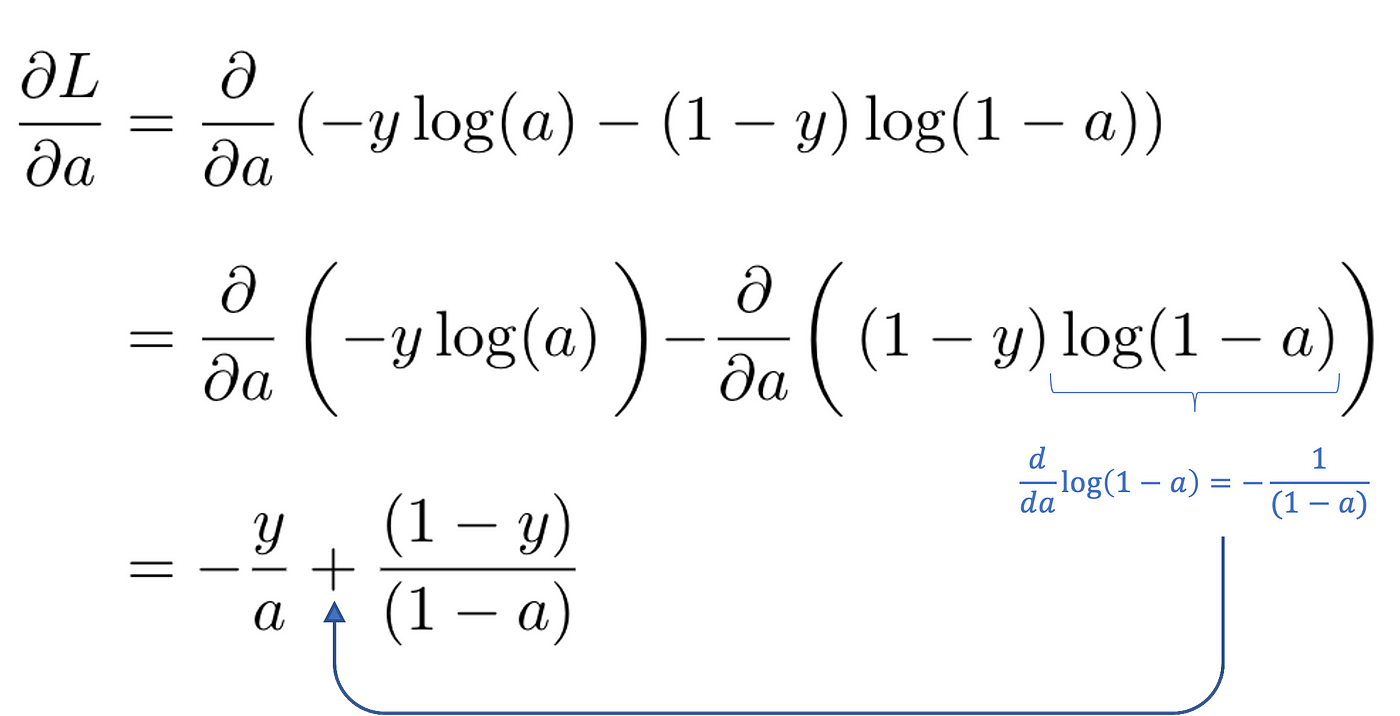

In [42]:
class CELoss():
    def forward(self, pred, target):
        """
        CrossEntropy алдагдлын функцийг хэрэгжүүлнэ.

        аргумент:
            pred   : мэдрэлийн сүлжээнээс урьдчилан таамагласан шошгуудыг
            target : үнэн шошго
        Буцаах:
            loss   : cross-entropy loss
        """
        self.yhat = pred
        self.y = target
        m = self.y.shape[0]
        # алдагдлыг тооцоолох
        term1 = self.y * np.log(self.yhat)
        term2 = (1-self.y) * np.log(1-self.yhat)
        print("self.y:", self.y.shape)
        print("self.yhat:", self.yhat.shape)
        print("term1:", term1.shape)
        print("term2:", term2.shape)
        loss = (-term1 + term2 ) / m
        self.output = loss
        return np.squeeze(self.output) # array-г нэг утганд хөрвүүлэх

    def backward(self):
        """
        loss_fn -ийн градинетуудыг урьдчилан таамагласан шошго руу тооцоолдог

        Буцаах:
         da : урьдчилан таамагласан шошгуудын уламжлал
        """
        # [урьдчилан таамагласан шошготой] холбоотой loss_fn уламжлал
        da = - self.y / self.yhat + (1 - self.y) / (1 - self.yhat)
        return da

## Загвар:

**Одоо ашиглах гэж байгаа мэдрэлийн сүлжээний архитектурыг хэрэгжүүлцгээе:**

- Манай загвар нь 2 далд давхарга, гаралтын давхаргатай болно.
- 2 `hidden layers` `(linear layers)` нь тус бүрдээ `16 units` дараа нь `ReLU` идэвхжүүлэх давхарга, `output layer` `(linear layers)` нь `10 unit` дараа нь `Sigmoid` давхаргуудтай болно.

Загварыг бүтээхэд шаардагдах давхаргуудыг цуглуулъя:

Shape of Inputs: torch.Size([60000, 784])
Shape of Targets: torch.Size([60000, 10])


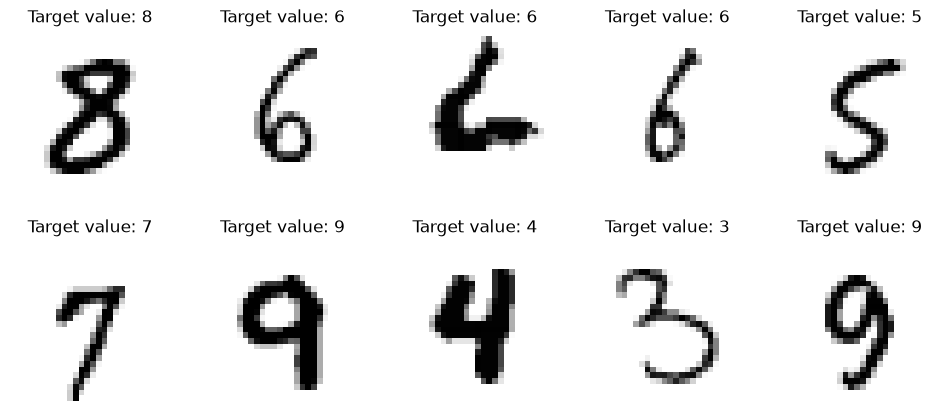

In [43]:
#collapse
print("Shape of Inputs:", x_train.shape)
print("Shape of Targets:", y_train.shape)

fig = plt.figure(figsize=(12,5))
for i in range(10):
    n = np.random.randint(len(x_train))
    val = x_train[n]
    ax = plt.subplot(2, 5, i+1)
    plt.imshow(val.reshape(28,28), cmap="binary")
    plt.title(f"Target value: {np.argmax(y_train[n])}")
    plt.axis("off")

**Initialize model parameters:**

In [44]:
#hide_output

nh1 = 16 # эхний нуугдмал давхарга дахь нэгжүүд
nh2 = 16 # 2-р нуугдмал давхарга дахь нэгжүүд
nh3 = 10 # гаралтын давхарга дахь нэгжүүдийн

w1  = np.random.randn(x_train.shape[1], nh1) * 0.01
b1  = np.zeros((1, nh1))

w2  = np.random.randn(nh1, nh2) * 0.01
b2  = np.zeros((1, nh2))

w3  = np.random.randn(nh2, nh3)
b3  = np.zeros((1, nh3))

w1.shape, b1.shape, w2.shape, b2.shape, w3.shape, b3.shape

((784, 16), (1, 16), (16, 16), (1, 16), (16, 10), (1, 10))

**Манай загварыг бүтээхэд шаардлагатай давхаргуудыг давхарлая :**

In [45]:
lin1    = Linear(w1,b1) # 1 hidden layer
relu1   = RelU()
lin2    = Linear(w2,b2) # 2nd hidden layer
relu2   = RelU()
lin3    = Linear(w3,b3) # output layer
sigmoid = Sigmoid()

loss_fn = CELoss() # loss_fn

### Шууд чиглэл:

In [46]:
# forward pass
z1   = lin1.forward(x_train[:50])
a1   = relu1.forward(z1)
z2   = lin2.forward(a1)
a2   = relu2.forward(z2)
z3   = lin3.forward(a2)
pred = a3 = sigmoid.forward(z3)
# print(pred)
# calculate loss
loss = loss_fn.forward(pred, y_train[:50])
print("Loss:", loss)

self.y: torch.Size([50, 10])
self.yhat: torch.Size([50, 10])
term1: torch.Size([50, 10])
term2: torch.Size([50, 10])
Loss: tensor([[-0.0138, -0.0139, -0.0138, -0.0138, -0.0139,  0.0138, -0.0139, -0.0138,
         -0.0138, -0.0137],
        [ 0.0138, -0.0139, -0.0138, -0.0139, -0.0139, -0.0138, -0.0139, -0.0138,
         -0.0139, -0.0137],
        [-0.0139, -0.0139, -0.0138, -0.0139,  0.0139, -0.0138, -0.0139, -0.0138,
         -0.0139, -0.0138],
        [-0.0139,  0.0139, -0.0138, -0.0138, -0.0139, -0.0139, -0.0139, -0.0138,
         -0.0139, -0.0138],
        [-0.0139, -0.0139, -0.0138, -0.0139, -0.0139, -0.0139, -0.0139, -0.0138,
         -0.0138,  0.0140],
        [-0.0139, -0.0138,  0.0139, -0.0139, -0.0139, -0.0139, -0.0139, -0.0138,
         -0.0139, -0.0138],
        [-0.0139,  0.0139, -0.0138, -0.0139, -0.0139, -0.0138, -0.0139, -0.0139,
         -0.0139, -0.0138],
        [-0.0138, -0.0139, -0.0138,  0.0139, -0.0139, -0.0139, -0.0139, -0.0138,
         -0.0138, -0.0136],
     

### Буцах чиглэл:

In [47]:
# backward pass
da3 = loss_fn.backward() # gradient of loss wrt to final output

dz3 = sigmoid.backward(da3)

da2, dw3, db3 = lin3.backward(dz3)

dz2 = relu2.backward(da2)
da1, dw2, db2 = lin2.backward(dz2)

dz1 = relu1.backward(da1)
_, dw1, db1 = lin1.backward(da1)

# параметрүүд болон градиентууд ижил хэлбэртэй эсэхийг шалгах.
# Ингэснээр бид шинэчлэлтийн байдлыг урьдчилан харж чадна
assert lin1.w.shape == dw1.shape
assert lin2.w.shape == dw2.shape
assert lin3.w.shape == dw3.shape

assert lin1.b.shape == db1.shape
assert lin2.b.shape == db2.shape
assert lin3.b.shape == db3.shape

grads: torch.Size([50, 10]) <class 'torch.Tensor'>
s: (50, 10) <class 'numpy.ndarray'>
grads: torch.Size([50, 10])
self.w.T: (10, 16)
self.inp.T: torch.Size([16, 50])
dw: torch.Size([16, 10])
db: torch.Size([1, 10])
da_prev: torch.Size([50, 16])
grads: (50, 16)
self.w.T: (16, 16)
self.inp.T: torch.Size([16, 50])
dw: torch.Size([16, 16])
db: (1, 16)
da_prev: (50, 16)
grads: (50, 16)
self.w.T: (16, 784)
self.inp.T: torch.Size([784, 50])
dw: torch.Size([784, 16])
db: (1, 16)
da_prev: (50, 784)


### parameter-үүдийг шинэчлэх:

In [48]:
# сургах хурдыг тохируулах
learning_rate = 0.0002


lin1.w -= learning_rate * np.array(dw1)
lin2.w -= learning_rate * np.array(dw2)
lin3.w -= learning_rate * np.array(dw3)

lin1.b -= learning_rate * np.array(db1)
lin2.b -= learning_rate * np.array(db2)
lin3.b -= learning_rate * np.array(db3)

Тэгэхээр, бидний загварыг сургахад эхлээд `forward pass`-ийн үед загварын `loss`-ыг тооцоолж, дараа нь загварын `parameters` руу `loss`-ийн градиентуудыг тооцоолдог. Үүний дараа эдгээр `gradients` нь `update the model parameters` ашиглагддаг. Бид энэхүү ажлын урсгалыг тодорхой тооны `iterations` эсвэл бидний `loss` хүссэн утганд хүрэх хүртэл үргэлжлүүлсээр байдаг.


Энэ алхмуудыг хэрэгжүүлцгээе.

### Бүгдийг нэгтгэвэл:

- **parameter-үүдийг эхлүүлэх:**

In [52]:
#hide_output

nh1 = 256 # эхний нуугдмал давхарга дахь нэгжүүдийн
nh2 = 64 # 2-р нуугдмал давхарга дахь нэгжүүдийн
nh3 = 10 # гаралтын давхарга дахь нэгжүүдийн

w1  = np.random.randn(x_train.shape[1], nh1) * 0.01
b1  = np.zeros((1, nh1))

w2  = np.random.randn(nh1, nh2) * 0.01
b2  = np.zeros((1, nh2))

w3  = np.random.randn(nh2, nh3)
b3  = np.zeros((1, nh3))

w1.shape, b1.shape, w2.shape, b2.shape, w3.shape, b3.shape

((784, 256), (1, 256), (256, 64), (1, 64), (64, 10), (1, 10))

Загварт зориулж 'Model' class бий болгох.

Энэ `Model` class нь манай мэдрэлийн сүлжээний бүх параметрүүдийг хадгалах болно. `forward` арга нь тухайн загварын `loss` (болон `predictions`) үүсгэхийн тулд сүлжээний `forward pass`-ийг тооцоолно. `backward` арга нь `loss`-ийн градинетуудыг загварын `parameters` хүргэхийн тулд сүлжээний `backward pass` тооцоолно. Эцэст нь `update` арга нь загварын параметрүүдийг шинэчлэх болно.

In [53]:
class Model:
    def __init__(self, learning_rate):
        """
        энгийн нерон сүлжээ
        `forward` загварын шууд тархалтыг тооцоолно
        `backward` загварын буцах тархалтыг тооцоолно
        `update_step` загварын парамертрүүдийг шинэчлэнэ
        """
        self.lin1    = Linear(w1,b1) # 1-р шугаман давхарга
        self.relu1   = RelU()        # 1-р идэвхжүүлэх давхарга

        self.lin2    = Linear(w2,b2) # 2-р шугаман давхарга
        self.relu2   = RelU()        # 2-р идэвхжүүлэх давхарга

        self.lin3    = Linear(w3,b3) # 3-р шугаман давхарга
        self.sigmoid = Sigmoid()     # 3-р идэвхжүүлэх давхарга

        self.loss_fn = CELoss()      # loss_fn

        # сургалтын хурд
        self.lr      = learning_rate
        # алдааг алхам бүрт хадгална
        self.losses  = []


    def forward(self, inp, calc_loss=True, targ=None):
        """
        Загварыг урагшлах алхмыг тооцоол. Нэмэлтээр энэ нь мөн алдагдлыг болон загварын урьдчилан таамаглалыг буцааж өгдөг.

        аргумент:
            inp       : сургалтын сан.
            calc_loss : зөвхөн урьдчилан таамаглал тооцоолдог бол загварын алдагдлыг тооцохгүй байх
            targ      : шошгууд.

        Тайлбар: ''алдагдал''-ыг тооцохын тулд 'шошго' заавал өгөх ёстой

        Буцаах:
            pred : 3-р идэвхжүүлэлтийн давхаргын үр дүн.
            loss : загвараа алдах , хэрэв 'шошго' өгөгдсөн бол.
        """
        out  = self.lin1.forward(inp)
        out  = self.relu1.forward(out)
        out  = self.lin2.forward(out)
        out  = self.relu2.forward(out)
        out  = self.lin3.forward(out)
        pred = self.sigmoid.forward(out)

        if calc_loss:
            assert targ is not None, "алдагдлыг тооцохын тулд заавал өгөх ёстой"
            loss = self.loss_fn.forward(pred, targ)

            self.losses.append(loss)
            return loss, pred
        else:
            return pred

    def _assert_shapes(self):
        """
        Загварын параметрүүдийн хэлбэр, градиентуудыг шалгана
        """
        print("self.lin1.w.shape:", self.lin1.w.shape)
        print("dw1.shape:", dw1.shape)
        print("self.lin2.w.shape:", self.lin2.w.shape)
        print("dw2.shape:", dw2.shape)
        print("self.lin3.w.shape:", self.lin3.w.shape)
        print("dw3.shape:", dw3.shape)
        print("self.lin1.b.shape:", self.lin1.b.shape)
        print("db1.shape:", db1.shape)
        print("self.lin2.b.shape:", self.lin2.b.shape)
        print("db2.shape:", db2.shape)
        print("self.lin3.b.shape:", self.lin3.b.shape)
        print("db3.shape:", db3.shape)
        assert self.lin1.w.shape == dw1.shape
        assert self.lin2.w.shape == dw2.shape
        assert self.lin3.w.shape == dw3.shape

        assert self.lin1.b.shape == db1.shape
        assert self.lin2.b.shape == db2.shape
        assert self.lin3.b.shape == db3.shape


    def backward(self):
        """
        Буцах алхмыг тооцоолж, параметрүүдийн градиентуудыг алдагдалтай буцааж өгдөг
        """
        da3 = np.array(self.loss_fn.backward())
        dz3 = self.sigmoid.backward(da3)
        da2, dw3, db3 = self.lin3.backward(dz3)

        dz2 = self.relu2.backward(da2)
        da1, dw2, db2 = self.lin2.backward(dz2)

        dz1 = self.relu1.backward(da1)  
        _, dw1, db1 = self.lin1.backward(dz1)

        self._assert_shapes()

        self.dws = [dw1, dw2, dw3]
        self.dbs = [db1, db2, db3]


    def update(self):
        """
        Шинэчлэх алхмыг гүйцэтгэнэ
        """
        self.lin1.w -= self.lr * self.dws[0]
        self.lin2.w -= self.lr * self.dws[1]
        self.lin3.w -= self.lr * self.dws[2]

        self.lin1.b -= self.lr * self.dbs[0]
        self.lin2.b -= self.lr * self.dbs[1]
        self.lin3.b -= self.lr * self.dbs[2]

In [54]:
nn = Model(learning_rate=0.0005)
epochs = 10 # сургалтын өгөгдлийн харах тоо

for n in range(epochs):
    loss, _ = nn.forward(x_train, calc_loss=True, targ=y_train)
    nn.backward()
    nn.update()
    print(f"Loss after interation {n} is {loss:.4f}")

self.y: torch.Size([60000, 10])
self.yhat: torch.Size([60000, 10])
term1: torch.Size([60000, 10])
term2: torch.Size([60000, 10])
grads: (60000, 10) <class 'numpy.ndarray'>
s: (60000, 10) <class 'numpy.ndarray'>
grads: (60000, 10)
self.w.T: (10, 64)
self.inp.T: torch.Size([64, 60000])
dw: torch.Size([64, 10])
db: (1, 10)
da_prev: (60000, 64)
grads: (60000, 64)
self.w.T: (64, 256)
self.inp.T: torch.Size([256, 60000])
dw: torch.Size([256, 64])
db: (1, 64)
da_prev: (60000, 256)
grads: (60000, 256)
self.w.T: (256, 784)
self.inp.T: torch.Size([784, 60000])
dw: torch.Size([784, 256])
db: (1, 256)
da_prev: (60000, 784)
self.lin1.w.shape: (784, 256)
dw1.shape: torch.Size([784, 16])
self.lin2.w.shape: (256, 64)
dw2.shape: torch.Size([16, 16])
self.lin3.w.shape: (64, 10)
dw3.shape: torch.Size([16, 10])
self.lin1.b.shape: (1, 256)
db1.shape: (1, 16)
self.lin2.b.shape: (1, 64)
db2.shape: (1, 16)
self.lin3.b.shape: (1, 10)
db3.shape: torch.Size([1, 10])


AssertionError: 

ValueError: x and y can be no greater than 2D, but have shapes (1,) and (1, 60000, 10)

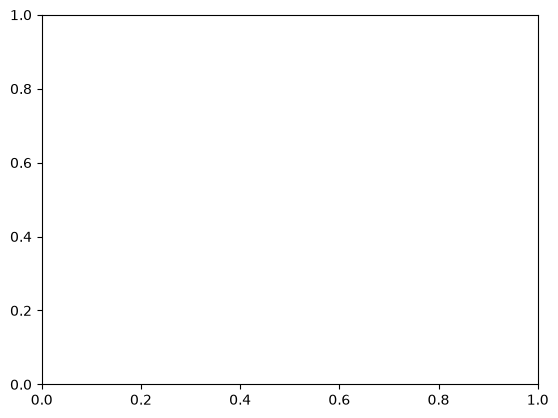

In [139]:
#collapse
plt.plot(nn.losses, color="teal")
plt.title("Loss per Iteration")
plt.xlabel("Iteration")
plt.ylabel("Loss");

## Загварын үнэн зөвийг тооцоолох

**'Баталгаажуулах' датасет дээр ''үнэн зөв''-ийг тооцоолон загвар үзүүлэлтээ шалгая**

Сургалтын багц дээрх үнэн зөв

In [ ]:
preds = nn.forward(x_train, calc_loss=False) # загвараас таамаглалуудыг үүсгэх
# accuracy тооцоолох
print(preds.shape, y_train.shape)
preds=np.argmax(preds, axis=1)
y_train=np.argmax(y_train, axis=1)
print(preds.shape, y_train.shape)

acc = np.sum(preds==y_train)/len(y_train)
print(acc)

(60000, 10) (60000, 10)
(60000,) (60000,)
0.60425


In [ ]:
print(preds[0], y_train[0])

3 5


Баталгаажуулах багц дээрх үнэн зөв

In [ ]:
preds = nn.forward(x_test, calc_loss=False) # загвараас таамаглалуудыг үүсгэх
# accuracy тооцоолох
preds=np.argmax(preds, axis=1)
y_test=np.argmax(y_test, axis=1)
acc = np.sum(preds==y_test)/len(y_test)
print(acc)

0.6068


> Тэмдэглэл: Манай загвар 'сургалтын' болон 'баталгаажуулах' багц дээр **'0.60'**-ийн 'үнэн зөв' хүрсэн!

## Загвараас таамаглалуудыг үүсгэх

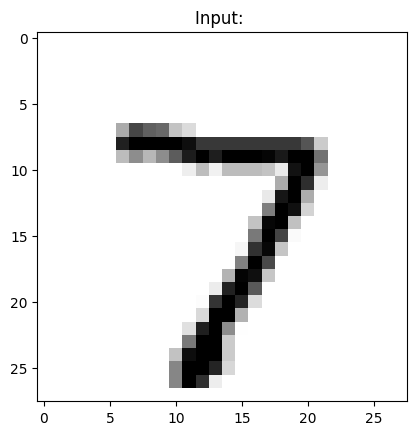

Predicted output: 7


In [ ]:
#collapse
test_inp = x_test[0] # баталгаажуулах багцаас нэгийг сонгон шалгая
plt.title("Input: ")

plt.imshow(test_inp.reshape(28,28), cmap="binary")
plt.show()

pred = nn.forward(test_inp, calc_loss=False)
predicted_val = np.argmax(pred)
print(f"Predicted output: {predicted_val}")

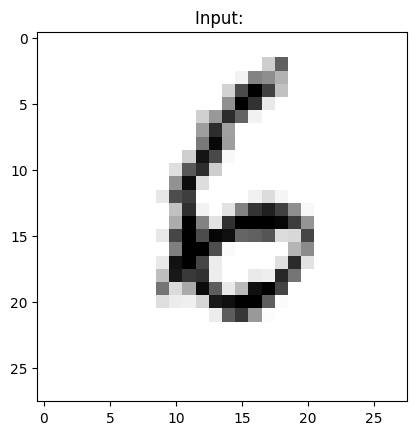

Predicted output: 6


In [ ]:
#collapse
test_inp = x_test[2000] # баталгаажуулах багцаас нэгийг сонгон шалгая
plt.title("Input: ")
plt.imshow(test_inp.reshape(28,28), cmap="binary")
plt.show()

pred = nn.forward(test_inp, calc_loss=False)
predicted_val = np.argmax(pred)
print(f"Predicted output: {predicted_val}")

# 2-р хэсэг
# CuPy ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.



# 3-р хэсэг
# Pytorch ашиглан питон дахь мэдрэлийн сүлжээг эхнээс кодчилох онол болон практик.

In [ ]:
import torch
import torch.nn as nn
from torch.optim import SGD, AdamW
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import Compose, ToTensor

train_dataset = TensorDataset(torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(x_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32))
transform = Compose([ToTensor()])
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
class SimpleNN(nn.Module):
    def __init__(self, input_size=28*28, hidden_size1=256, hidden_size2=64, output_size=10):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden_size2, output_size)
        self.sigmoid = nn.Sigmoid()
        self.fc_b1 = nn.Linear(512,128)
        self.fc_b2 = nn.Linear(512,128)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        # print(x.shape)
        x1, x2 = x[:, :512], x[:, 512:]
        # print(x1.shape, x2.shape)
        x1 = self.fc_b1(x1)
        x2 = self.fc_b2(x2)
        x = self.fc2(x)

        x = self.relu2(x + x1 + x2)
        x = self.fc3(x)
        x = self.sigmoid(x)
        return x
def train_model(model, train_loader, criterion, optimizer, num_epochs):
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            # print(f"inputs shape: {inputs.shape}, labels shape: {labels.shape}")
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        epoch_loss = running_loss / len(train_loader.dataset)
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}')
def evaluate_model(model, test_loader, save=True):
    model.eval()
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            _, labels_max = torch.max(labels.data, 1)
            total += labels.size(0)
            correct += (predicted == labels_max).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels_max.cpu().numpy())
    accuracy = correct / total
    print(f'Accuracy: {accuracy:.4f}')
    global best_test_accuracy
    if save:
        if accuracy > best_test_accuracy:
            best_test_accuracy = accuracy
            torch.save(model.state_dict(), "best_model.pth")
            print("Best model saved with accuracy: {:.4f}".format(best_test_accuracy))
    return accuracy, all_preds, all_labels
# epochs = 20
# model = SimpleNN()
# criterion = CrossEntropyLoss()
# optimizer = AdamW(model.parameters(), lr=0.0003, weight_decay=1e-5)
# best_test_accuracy = 0.0
# for epoch in range(epochs):
#     print(f"Epoch {epoch+1}/{epochs}")

#     train_model(model, train_loader, criterion, optimizer, num_epochs=1)
#     evaluate_model(model, test_loader)
# Энгийн 3 давхаргатай сүлжээг байгуулах сургах
epochs = [50]
learning_rates = [0.0001]
optimizers = [AdamW]
batch_sizes = [64]
linear_sizes = [(1024, 128)] # grid search , random search хийхэд тохиромжтой
best_hyperparams = None
global_best_test_accuracy = 0.0
for epoch in epochs:
    for lr in learning_rates:
        for optimizer_class in optimizers:
            for batch_size in batch_sizes:
                for linear_size in linear_sizes:
                    print(f"Training with epochs={epoch}, lr={lr}, optimizer={optimizer_class.__name__}, batch_size={batch_size}, linear_size={linear_size}")
                    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
                    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
                    model = SimpleNN(hidden_size1=linear_size[0], hidden_size2=linear_size[1])
                    criterion = CrossEntropyLoss()
                    optimizer = optimizer_class(model.parameters(), lr=lr, weight_decay=1e-5)
                    best_test_accuracy = 0.0
                    for e in range(epoch):
                        print(f"Epoch {e+1}/{epoch}")
                        train_model(model, train_loader, criterion, optimizer, num_epochs=1)
                        _,_,_ = evaluate_model(model, test_loader)
                        if global_best_test_accuracy < best_test_accuracy:
                            best_hyperparams = (epoch, lr, optimizer_class.__name__, batch_size, linear_size)
                            global_best_test_accuracy = best_test_accuracy


/var/folders/83/ql9qgbqs3m5b_sq_z5jb9k300000gn/T/ipykernel_55711/3122216929.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  train_dataset = TensorDataset(torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
/var/folders/83/ql9qgbqs3m5b_sq_z5jb9k300000gn/T/ipykernel_55711/3122216929.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_dataset = TensorDataset(torch.tensor(x_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32))


Training with epochs=50, lr=0.0001, optimizer=AdamW, batch_size=64, linear_size=(1024, 128)
Epoch 1/50
Epoch 1/1, Loss: 1.6542
Accuracy: 0.9231
Best model saved with accuracy: 0.9231
Epoch 2/50
Epoch 1/1, Loss: 1.5351
Accuracy: 0.9400
Best model saved with accuracy: 0.9400
Epoch 3/50
Epoch 1/1, Loss: 1.5173
Accuracy: 0.9490
Best model saved with accuracy: 0.9490
Epoch 4/50
Epoch 1/1, Loss: 1.5068
Accuracy: 0.9545
Best model saved with accuracy: 0.9545
Epoch 5/50
Epoch 1/1, Loss: 1.4996
Accuracy: 0.9617
Best model saved with accuracy: 0.9617
Epoch 6/50
Epoch 1/1, Loss: 1.4941
Accuracy: 0.9661
Best model saved with accuracy: 0.9661
Epoch 7/50
Epoch 1/1, Loss: 1.4894
Accuracy: 0.9691
Best model saved with accuracy: 0.9691
Epoch 8/50
Epoch 1/1, Loss: 1.4857
Accuracy: 0.9721
Best model saved with accuracy: 0.9721
Epoch 9/50
Epoch 1/1, Loss: 1.4826
Accuracy: 0.9720
Epoch 10/50
Epoch 1/1, Loss: 1.4803
Accuracy: 0.9750
Best model saved with accuracy: 0.9750
Epoch 11/50
Epoch 1/1, Loss: 1.4782


In [29]:
print(global_best_test_accuracy)

0.9834



# 4-р хэсэг
# Сургасан загварт дүн шинжилгээ хийх туслах [параметрүүдийг тохируулах](https://pytorch.org/tutorials/beginner/hyperparameter_tuning_tutorial.html)

In [ ]:
# Hyperparameter tuning implementation

Accuracy: 0.9834
F1 Score: 0.9834
Precision: 0.9834
Recall: 0.9834


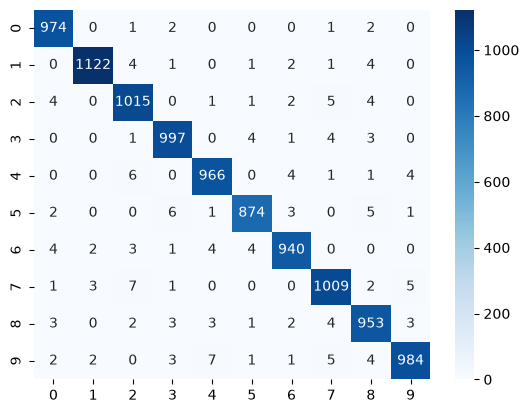

In [31]:
# evaluation of the best model
import sklearn.metrics as metrics

import seaborn as sns
model = SimpleNN(hidden_size1=1024, hidden_size2=128)
model.load_state_dict(torch.load("best_model.pth"))
accuracy ,all_preds, all_labels = evaluate_model(model, test_loader)
confusion_matrix = metrics.confusion_matrix(all_labels, all_preds)
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
# other F1 score, precision, recall, etc. can be calculated using sklearn.metrics functions
f1_score = metrics.f1_score(all_labels, all_preds, average='weighted')
precision = metrics.precision_score(all_labels, all_preds, average='weighted')
recall = metrics.recall_score(all_labels, all_preds, average='weighted')
print(f"F1 Score: {f1_score:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
# AUC



In [ ]:
# KFold
from sklearn.model_selection import KFold
fold = KFold(n_splits=6, shuffle=True, random_state=42)
datasets = fold.split(x_train, y_train)
# torch data
# fold train
# fold eval
# cross validation
# best model
# AUC

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sn
import pandas as pd

# y_pred = []
# y_true = []

# # iterate over test data
# for inputs, labels in testloader:
#         output = net(inputs) # Feed Network

#         output = (torch.max(torch.exp(output), 1)[1]).data.cpu().numpy()
#         y_pred.extend(output) # Save Prediction

#         labels = labels.data.cpu().numpy()
#         y_true.extend(labels) # Save Truth



# # Build confusion matrix
# cf_matrix = confusion_matrix(y_true, y_pred)
# df_cm = pd.DataFrame(cf_matrix / np.sum(cf_matrix, axis=1)[:, None], index = [i for i in classes],
#                      columns = [i for i in classes])
# plt.figure(figsize = (12,7))
# sn.heatmap(df_cm, annot=True)
# plt.savefig('output.png')

ModuleNotFoundError: No module named 'seaborn'